:::{danger} Ejercicio sin validar: no usar para tomar decisiones
Este cuaderno **no ha sido validado por una persona experta** en modelación de tsunamis. Es un ejercicio de reproducibilidad y de aprendizaje. Sus resultados **no deben usarse para tomar decisiones** de gestión del riesgo, ordenamiento territorial, diseño de obras, planes de evacuación ni alertas.

Falta, como mínimo: la revisión por una persona experta; la distribución de deslizamiento real del evento (la geometría de la falla es un supuesto); la validación contra observaciones de 1979 que se contradicen entre fuentes (véase el cuaderno 3); y un modelo no lineal con cálculo de inundación.
:::

# Cuaderno 2: Simulación del tsunami de 1979

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/scr-ungrd/cuadernos-reproducibles-crc002/blob/main/notebooks/02-simulation.ipynb)

Propagación del tsunami del 12 de diciembre de 1979 con **ecuaciones de aguas someras lineales (LSWE)** en **NumPy puro**. Cambios respecto a la
versión 1:

| | Versión 1 | Versión 2 |
|---|---|---|
| Fuente | Onda en N con amplitud de calibración de 8 m (pico inicial de 16 m) | Deformación del fondo de una falla rectangular con el modelo de Okada (1985); sin parámetro de calibración |
| Esquema | Lax-Friedrichs (primer orden, muy difusivo) | Malla escalonada *forward-backward* (sin difusión numérica) |
| Posición de la fuente | Franja N–S ligada a la celda de costa más oriental | Falla ligada al epicentro |
| Fronteras | Reflejantes (Neumann) | Abiertas (radiación) |
| Dominio | 0,5–3,5° N, 79,5–77° O | 0,2° S–4,2° N, 81,2–76,9° O |

**Runtime:** CPU, unos 4 minutos. **Se ejecuta el cuaderno 1 antes** (o se descarga el DEM automáticamente).

In [1]:
import sys, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio', 'pyproj'], check=True)
import rasterio
from rasterio.crs import CRS
from pyproj import Transformer

WORK = Path('/content') if IN_COLAB else Path('.')
OUT = WORK / 'output'
OUT.mkdir(exist_ok=True)
RAW = 'https://raw.githubusercontent.com/scr-ungrd/cuadernos-reproducibles-crc002/main/data/'

def datos(nombre):
    """Ruta de un archivo de data/: local (../data) o descargado del repositorio (Colab)."""
    for base in (Path('../data'), Path('data'), WORK / 'data'):
        if (base / nombre).exists():
            return base / nombre
    import requests
    destino = WORK / 'data'
    destino.mkdir(exist_ok=True)
    r = requests.get(RAW + nombre, timeout=120)
    r.raise_for_status()
    (destino / nombre).write_bytes(r.content)
    return destino / nombre

# Epicentro del 12-dic-1979 (1,584° N, 79,386° O: tabla 1 de Herd et al., 1981, hipocentro del NEIS)
EPI = (-79.386, 1.584)                       # (lon, lat)
CRS_UTM = CRS.from_epsg(32617)               # UTM 17N, meridiano central 81° O (error de escala < 0,2 % en el dominio)
TR = Transformer.from_crs(4326, 32617, always_xy=True)
G = 9.81

def ejes_lonlat(ax, paso=1):
    """Marcas de longitud y latitud sobre un mapa en coordenadas UTM (km); oeste a la izquierda, norte arriba."""
    lons = np.arange(-81, -76.5, paso); lats = np.arange(0, 4.5, paso)
    xl, yl = ax.get_xlim(), ax.get_ylim()
    ax.set_xticks([TR.transform(l, 2.0)[0] / 1e3 for l in lons]); ax.set_xticklabels([f'{abs(l):g}°O' for l in lons])
    ax.set_yticks([TR.transform(-79.0, l)[1] / 1e3 for l in lats]); ax.set_yticklabels([f'{l:g}°N' for l in lats])
    ax.set_xlim(xl); ax.set_ylim(yl)
    ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')

## 1. Escenario sísmico

La magnitud (**Mw 8,3**) viene de la literatura: Yoshimoto et al. (2017), citado por Escobar et al. (2020) y Ávila-Guzmán et al. (2026);
la versión 1 usaba 8,2. Esos trabajos tomaron la distribución de deslizamiento de Poveda y Pulido (2019). **No se tienen a la mano las dimensiones y la
geometría de ese modelo**, así que aquí se usa un **escenario sintético de deslizamiento uniforme sobre una falla rectangular**
cuyos parámetros geométricos son **supuestos, por verificar**:

| Parámetro | Valor | Estado |
|---|---|---|
| Mw | 8,3 | Literatura (Yoshimoto et al., 2017) |
| Epicentro | 1,584° N, 79,386° O | Herd et al. (1981), tabla 1 |
| Longitud × ancho | 200 × 80 km | Supuesto (orden de magnitud para Mw 8,3) |
| Rumbo / buzamiento / ángulo de desplazamiento | 30° / 15° / 90° (inverso) | Supuesto (margen colombo-ecuatoriano con rumbo NNE) |
| Profundidad del borde superior | 12 km (el borde inferior queda a ~33 km) | Supuesto; el hipocentro de 33 km se ubica en el centro del borde inferior |
| Módulo de rigidez, Poisson | 30 GPa, 0,25 | Valores típicos |
| Deslizamiento | M₀ / (μ·L·W) ≈ 7,4 m | Derivado |

La deformación vertical del fondo se traslada tal cual a la superficie del agua (condición inicial instantánea, sin filtro por la columna de agua
ni componente horizontal sobre el talud).

In [2]:
ESC = dict(Mw=8.3, strike=30., dip=15., rake=90., L=200e3, W=80e3, top_depth=12e3, mu=3e10, nu=0.25)
DX, DT, T_END, OUT_EVERY = 450., 1.0, 6600., 240.   # m, s, s, s (110 min simulados, 28 instantáneas; Buenaventura recibe la primera ola a los 99 min)

def okada_uz(x, y, d, L, W, strike_deg, dip_deg, rake_deg, slip, nu=0.25):
    """Desplazamiento vertical en superficie (m, positivo hacia arriba) de una falla rectangular en un semiespacio elástico
    (Okada, 1985). (x, y) = (este, norte) en m respecto a la proyección en superficie del punto medio del borde INFERIOR de la falla;
    d = profundidad del borde superior (m); L = longitud a lo largo del rumbo; W = ancho a lo largo del buzamiento (m)."""
    k = 1.0 - 2.0 * nu                                  # mu / (lambda + mu)
    st, dl, rk = np.radians(strike_deg), np.radians(dip_deg), np.radians(rake_deg)
    sd, cd = np.sin(dl), np.cos(dl)
    X = x * np.sin(st) + y * np.cos(st)                 # a lo largo del rumbo
    Y = -x * np.cos(st) + y * np.sin(st)                # perpendicular, hacia el buzamiento
    d_inf = d + W * sd
    U1, U2 = slip * np.cos(rk), slip * np.sin(rk)
    p = Y * cd + d_inf * sd
    q = Y * sd - d_inf * cd
    def f(xi, eta):
        """Contribución de una esquina del plano de falla al desplazamiento vertical (Okada, 1985); el cuaderno la combina en las cuatro esquinas (notación de Chinnery)."""
        R = np.sqrt(xi**2 + eta**2 + q**2); Xq = np.sqrt(xi**2 + q**2)
        dt = eta * sd - q * cd
        with np.errstate(all='ignore'):
            I4 = k * (np.log(R + dt) - sd * np.log(R + eta)) / cd
            I5 = np.where(np.abs(xi) < 1e-9, 0.0,
                          k * 2.0 / cd * np.arctan((eta * (Xq + q * cd) + Xq * (R + Xq) * sd) / (xi * (R + Xq) * cd)))
            ss = -(dt * q / (R * (R + eta)) + q * sd / (R + eta) + I4 * sd)
            ds = -(dt * q / (R * (R + xi)) + sd * np.arctan(xi * eta / (q * R)) - I5 * sd * cd)
        return (U1 * ss + U2 * ds) / (2 * np.pi)
    xs = X + L / 2.0
    return f(xs, p) - f(xs, p - W) - f(xs - L, p) + f(xs - L, p - W)

# --- Verificación contra una implementación independiente (pyrocko, okada_ext; mismos parámetros) ---
_xs = np.array([-40e3, -10e3, 0, 20e3, 60e3, 100e3]); _ys = np.array([30e3, -20e3, 0, 40e3, -50e3, 10e3])
_ref = {(30., 15., 90., 10e3): [1.8464649, -0.704549, -0.6910644, -0.384285, -0.0361739, -0.0202239],
        (200., 25., 90., 5e3): [-0.1313679, -0.2849464, -0.1790315, 0.0740588, 0.0022756, 0.0002734],
        (75., 10., 110., 15e3): [1.3561887, -0.6388427, -0.8413563, 0.7408425, -0.0610156, -0.0539045]}
for (st_, dp_, rk_, d_), ref in _ref.items():
    err = np.abs(okada_uz(_xs, _ys, d_, 100e3, 50e3, st_, dp_, rk_, 5.0) - np.array(ref)).max()
    assert err < 1e-5, f'Okada no coincide con la referencia: {err}'
print('✓ Okada (1985) reproduce los valores de referencia de pyrocko (error máx. < 1e-5 m, 3 geometrías)')

✓ Okada (1985) reproduce los valores de referencia de pyrocko (error máx. < 1e-5 m, 3 geometrías)


In [3]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

def a_utm(ruta, dx):
    """Reproyecta el DEM a UTM 17N con celdas de `dx` m (interpolación bilineal). Devuelve la malla (m, NaN sin dato) y su transformación afín."""
    with rasterio.open(ruta) as src:
        tf, w, h = calculate_default_transform(src.crs, CRS_UTM, src.width, src.height, *src.bounds, resolution=dx)
        arr = np.full((h, w), np.nan, 'float32')
        reproject(rasterio.band(src, 1), arr, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=tf, dst_crs=CRS_UTM, resampling=Resampling.bilinear, dst_nodata=np.nan)
    return arr, tf

def cargar_H(dx):
    """Profundidad en reposo H (m; 0 en tierra y en celdas sin dato) y transformación afín."""
    ruta = OUT / 'dem_utm17_450m.tif'
    if dx == 450. and ruta.exists():
        with rasterio.open(ruta) as s: dem, tf = s.read(1), s.transform
    else:
        try:
            geo = datos('dem_tumaco_noaa_15s.tif')
        except Exception as e:
            raise RuntimeError('Ejecute primero el cuaderno 1 (no se encontró el DEM).') from e
        dem, tf = a_utm(geo, dx)
    return np.where(np.isnan(dem), 0.0, np.maximum(-dem, 0.0)), tf

def eta_inicial(tf, shape, esc):
    """Deformación vertical del fondo (m) en cada celda para el escenario `esc`; devuelve (eta0, deslizamiento)."""
    M0 = 10 ** (1.5 * esc['Mw'] + 9.1)
    slip = M0 / (esc['mu'] * esc['L'] * esc['W'])
    ex, ey = TR.transform(*EPI)
    # El epicentro es la proyección del punto medio del borde inferior (hipocentro supuesto)
    ny, nx = shape
    X, Y = np.meshgrid(tf.c + tf.a * (np.arange(nx) + .5) - ex, tf.f + tf.e * (np.arange(ny) + .5) - ey)
    uz = okada_uz(X, Y, esc['top_depth'], esc['L'], esc['W'], esc['strike'], esc['dip'], esc['rake'], slip, esc['nu'])
    return uz.astype('float32'), slip

H, tf = cargar_H(DX)
ny, nx = H.shape
eta0, slip = eta_inicial(tf, H.shape, ESC)
eta0 = np.where(H > 0, eta0, 0.0)          # la deformación solo mueve agua donde hay océano
print(f'Malla {nx}×{ny} de {DX:.0f} m | deslizamiento {slip:.1f} m | η₀: máx. {eta0.max():.2f} m, mín. {eta0.min():.2f} m')

Malla 1065×1084 de 450 m | deslizamiento 7.4 m | η₀: máx. 3.14 m, mín. -1.26 m


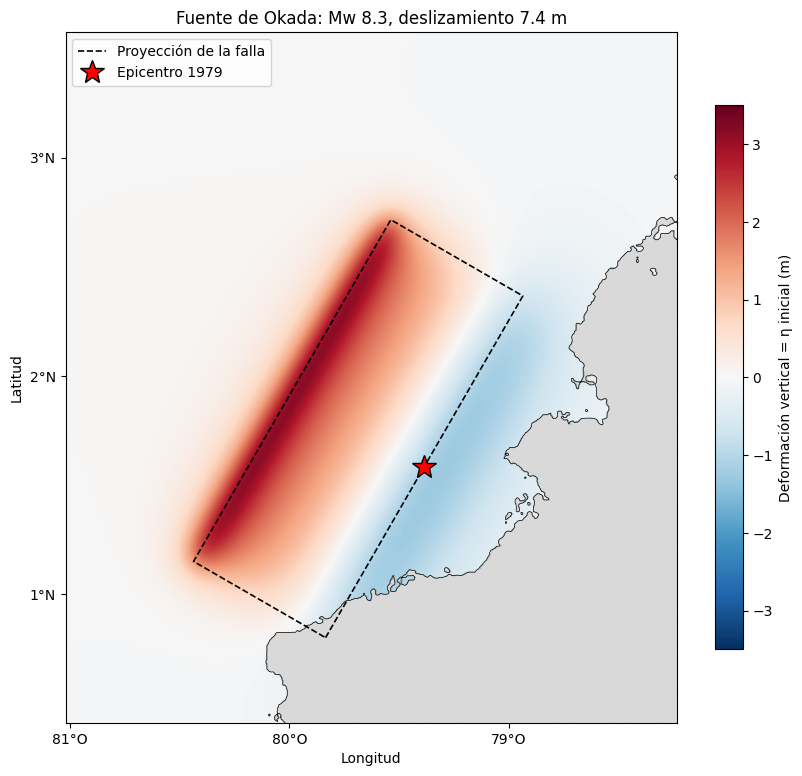

In [4]:
def contorno_falla(esc, L=None, W=None):
    """Contorno del plano de falla proyectado en superficie, en km UTM 17N, como polígono cerrado de cinco vértices a partir del epicentro y del escenario `esc`."""
    ex, ey = TR.transform(*EPI)
    st = np.radians(esc['strike']); up = np.radians(esc['strike'] + 270.)
    sh = esc['W'] * np.cos(np.radians(esc['dip']))
    return np.array([(ex + a * esc['L'] / 2 * np.sin(st) + b * sh * np.sin(up),
                      ey + a * esc['L'] / 2 * np.cos(st) + b * sh * np.cos(up)) for a, b in [(-1, 0), (1, 0), (1, 1), (-1, 1), (-1, 0)]]) / 1e3

ext = [tf.c / 1e3, (tf.c + tf.a * nx) / 1e3, (tf.f + tf.e * ny) / 1e3, tf.f / 1e3]
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.imshow(np.where(H > 0, 0.97, 0.85), cmap='gray', vmin=0, vmax=1, extent=ext)
im = ax.imshow(np.where(H > 0, eta0, np.nan), cmap='RdBu_r', vmin=-3.5, vmax=3.5, extent=ext)
ax.contour(np.linspace(ext[0], ext[1], nx), np.linspace(ext[3], ext[2], ny), H, levels=[0.5], colors='k', linewidths=.5)
cf = contorno_falla(ESC); ax.plot(cf[:, 0], cf[:, 1], 'k--', lw=1.2, label='Proyección de la falla')
ex, ey = TR.transform(*EPI); ax.plot(ex / 1e3, ey / 1e3, '*', c='red', mec='k', ms=18, label='Epicentro 1979')
ax.legend(loc='upper left'); plt.colorbar(im, shrink=.75, label='Deformación vertical = η inicial (m)')
ax.set_xlim(tf.c / 1e3 + 20, tf.c / 1e3 + 330); ax.set_ylim(tf.f / 1e3 - 420, tf.f / 1e3 - 70); ejes_lonlat(ax)
ax.set_title(f'Fuente de Okada: Mw {ESC["Mw"]}, deslizamiento {slip:.1f} m'); plt.tight_layout()
plt.savefig(WORK / 'fuente_okada.png', dpi=130); plt.show()

## 2. Solver LSWE en malla escalonada

Ecuaciones lineales con profundidad en reposo $H$ fija ($M = Hu$, $N = Hv$ son los flujos por unidad de ancho):

$$
\frac{\partial \eta}{\partial t} + \frac{\partial M}{\partial x} + \frac{\partial N}{\partial y} = 0, \qquad
\frac{\partial M}{\partial t} + gH\frac{\partial \eta}{\partial x} = 0, \qquad
\frac{\partial N}{\partial t} + gH\frac{\partial \eta}{\partial y} = 0 .
$$

$\eta$ se define en el centro de las celdas y $M$, $N$ en sus caras (malla C de Arakawa); primero se actualiza $\eta$ y luego los flujos con el $\eta$ nuevo
(*forward-backward*), un esquema clásico de diferencias finitas para aguas someras. Es de segundo orden en el espacio y no añade difusión
numérica. El reposo ($\eta=0$) es solución exacta para cualquier fondo. Las caras entre una celda de agua y una de tierra tienen flujo nulo (pared en
la línea de costa); las fronteras del dominio son abiertas con la condición de radiación $M = \pm\sqrt{gH}\,\eta$. **No hay fricción ni términos no
lineales**: el modelo no calcula inundación en tierra.

In [5]:
def run_lswe(H, dx, eta0, dt, t_end, out_every, estaciones=None, umbral=0.1, frontera_ns='abierta'):
    """LSWE en malla C. Devuelve η máxima, tiempo del primer ascenso (η > umbral), instantáneas y series en `estaciones` (lista de (fila, col))."""
    ny, nx = H.shape
    mar = H > 0
    eta = np.where(mar, eta0, 0.0).astype('float64')
    M = np.zeros((ny, nx + 1)); N = np.zeros((ny + 1, nx))
    Hx = np.where(mar[:, :-1] & mar[:, 1:], np.minimum(H[:, :-1], H[:, 1:]), 0.0)
    Hy = np.where(mar[:-1, :] & mar[1:, :], np.minimum(H[:-1, :], H[1:, :]), 0.0)
    c = np.sqrt(G * H)
    cfl = c.max() * dt * np.sqrt(2.0) / dx
    assert cfl < 1.0, f'CFL = {cfl:.2f} >= 1'
    nsteps = int(round(t_end / dt)); cada = int(round(out_every / dt))
    maxeta = eta.copy(); tarr = np.full(H.shape, np.nan, 'float32')
    snap_t, snaps = [0.0], [eta.astype('float16')]
    if estaciones:
        ij = np.array(estaciones); rec = np.zeros((nsteps + 1, len(ij)), 'float32'); rec[0] = eta[ij[:, 0], ij[:, 1]]
    else:
        rec = None
    gdt = G * dt / dx
    for n in range(1, nsteps + 1):
        eta -= dt / dx * ((M[:, 1:] - M[:, :-1]) + (N[1:, :] - N[:-1, :]))
        M[:, 1:-1] -= gdt * Hx * (eta[:, 1:] - eta[:, :-1])
        N[1:-1, :] -= gdt * Hy * (eta[1:, :] - eta[:-1, :])
        M[:, 0] = -c[:, 0] * eta[:, 0];  M[:, -1] = c[:, -1] * eta[:, -1]
        if frontera_ns == 'abierta':
            N[0, :] = -c[0, :] * eta[0, :];  N[-1, :] = c[-1, :] * eta[-1, :]
        np.maximum(maxeta, eta, out=maxeta)
        if n % 5 == 0:
            nuevo = np.isnan(tarr) & (eta > umbral); tarr[nuevo] = n * dt
        if rec is not None:
            rec[n] = eta[ij[:, 0], ij[:, 1]]
        if n % cada == 0:
            snap_t.append(n * dt); snaps.append(eta.astype('float16'))
    return dict(maxeta=maxeta.astype('float32'), tarr=tarr, snap_t=np.array(snap_t), snaps=np.array(snaps), rec=rec, dt=dt, cfl=cfl)

print('✓ Solver definido')

✓ Solver definido


## 3. Verificación del solver

Una onda plana en un canal de 1 000 m de profundidad debe viajar a $c=\sqrt{gH}$ sin perder amplitud. Se compara con el esquema de Lax-Friedrichs de la
versión 1 (reimplementado aquí solo para la prueba).

In [6]:
def lf_step(eta, u, v, H0, dx, dt, g=G):
    """Esquema de Lax-Friedrichs de la versión 1 (sin fricción), solo para comparar."""
    Qu, Qv = H0 * u, H0 * v; c_ = slice(1, -1); p = slice(2, None); m = slice(0, -2)
    avg = lambda A: 0.25 * (A[c_, p] + A[c_, m] + A[p, c_] + A[m, c_])
    en, un, vn = eta.copy(), u.copy(), v.copy()
    en[c_, c_] = avg(eta) - dt / (2 * dx) * (Qu[c_, p] - Qu[c_, m]) - dt / (2 * dx) * (Qv[p, c_] - Qv[m, c_])
    un[c_, c_] = avg(u) - dt * g * (eta[c_, p] - eta[c_, m]) / (2 * dx)
    vn[c_, c_] = avg(v) - dt * g * (eta[p, c_] - eta[m, c_]) / (2 * dx)
    for a in (en, un, vn):
        a[0, :] = a[1, :]; a[-1, :] = a[-2, :]; a[:, 0] = a[:, 1]; a[:, -1] = a[:, -2]
    return en, un, vn

# Canal plano: pulso gaussiano (σ = 5 km, longitud de onda ~35 km), amplitud 1 m, se parte en dos ondas de 0,5 m
nxt, nyt, dxt, Ht, Tt = 800, 24, 450., 1000., 1200
x = (np.arange(nxt) + .5) * dxt; x0 = nxt * dxt / 2
e0 = np.tile(np.exp(-0.5 * ((x - x0) / 5e3) ** 2), (nyt, 1))
r = run_lswe(np.full((nyt, nxt), Ht), dxt, e0, 1.0, Tt, Tt, frontera_ns='pared')
der = r['snaps'][-1].astype('float64')[nyt // 2, nxt // 2:]
amp_C = der.max(); pos_C = (np.argmax(der) + nxt // 2) * dxt - x0
e, u, v = e0.copy(), np.zeros_like(e0), np.zeros_like(e0)
for _ in range(Tt): e, u, v = lf_step(e, u, v, np.full((nyt, nxt), Ht), dxt, 1.0)
amp_LF = e[nyt // 2, nxt // 2:].max()
print(f'Distancia esperada c·t = {np.sqrt(G*Ht)*Tt/1e3:.1f} km | malla escalonada: pico {pos_C/1e3:.1f} km, amplitud {amp_C:.3f} m (ideal 0,500)')
print(f'Lax-Friedrichs (versión 1): amplitud {amp_LF:.3f} m → conserva {100*amp_LF/0.5:.0f} % tras {np.sqrt(G*Ht)*Tt/1e3:.0f} km')
assert amp_C > 0.49 and abs(pos_C - np.sqrt(G * Ht) * Tt) < 2 * dxt, 'el solver escalonado no propaga bien la onda plana'

# Reposo: sin fuente no hay movimiento
r0 = run_lswe(H, DX, np.zeros_like(eta0), DT, 60., 60.)
assert np.abs(r0['maxeta']).max() == 0.0
print('✓ Reposo exacto; ✓ onda plana')

Distancia esperada c·t = 118.9 km | malla escalonada: pico 118.3 km, amplitud 0.500 m (ideal 0,500)
Lax-Friedrichs (versión 1): amplitud 0.215 m → conserva 43 % tras 119 km


✓ Reposo exacto; ✓ onda plana


## 4. Estaciones

Cada estación de la tabla de observaciones se lleva a la **celda de mar más cercana con profundidad de al menos 10 m y a menos de 10 km**. Con 450 m de
resolución y sin inundación, una celda en la línea de costa (profundidades de 0 a pocos metros) no es una lectura representativa. Las estaciones cuya
coordenada cae tierra adentro, en un estuario somero o fuera del dominio se **excluyen y se declara**. Excepción: la estación con una primera ola positiva medida en un
mareógrafo (Buenaventura) usa la celda más cercana de **al menos 5 m** y a menos de 3 km, porque con 10 m el punto quedaría a 15 km y el tiempo de viaje cambiaría en decenas de minutos;
se compara solo el primer arribo (umbral de 0,1 m), no la amplitud.

In [7]:
obs = pd.read_csv(datos('observaciones_1979.csv'))

def elegir_celda(H, tf, dx, lon, lat, hmin=10., rmax=10e3):
    """Celda de mar más cercana a (`lon`, `lat`) con profundidad de al menos `hmin` m y a no más de `rmax` m. Devuelve (índice, distancia en km, profundidad, estado); el índice es None si cae fuera del dominio o no hay mar cercano."""
    ny, nx = H.shape; x, y = TR.transform(lon, lat)
    ri, ci = (y - tf.f) / tf.e - .5, (x - tf.c) / tf.a - .5
    if not (0 <= ri < ny and 0 <= ci < nx):
        return None, np.nan, np.nan, 'fuera del dominio'
    w = np.argwhere(H >= hmin); d = np.hypot(w[:, 0] - ri, w[:, 1] - ci) * dx; k = d.argmin()
    if d[k] > rmax:
        return None, d[k] / 1e3, np.nan, f'sin mar de ≥ 10 m a < 10 km (el más cercano, a {d[k]/1e3:.0f} km)'
    return tuple(int(v) for v in w[k]), d[k] / 1e3, H[tuple(w[k])], 'ok'

def tabla_estaciones(H, tf, dx):
    """Asigna a cada observación de 1979 su celda de mar. Los mareógrafos (tiempo de primera ola positiva) usan un umbral de 5 m y 3 km; los demás, 10 m y 10 km."""
    filas = []
    for _, r in obs.iterrows():
        mareografo = r.t_obs_tipo == 'primera_ola_positiva'
        ij, d, h, est = elegir_celda(H, tf, dx, r.lon, r.lat, hmin=5. if mareografo else 10., rmax=3e3 if mareografo else 10e3)
        filas.append(dict(estacion=r.estacion, fila=-1 if ij is None else ij[0], col=-1 if ij is None else ij[1],
                          dist_celda_km=d, H_celda_m=h, estado=est))
    return pd.DataFrame(filas)

est = tabla_estaciones(H, tf, DX)
est

,estacion,fila,col,dist_celda_km,H_celda_m,estado
0,Tumaco,577,601,4.698234,10.701995,ok
1,San Juan de la Costa,457,638,2.354661,20.976875,ok
2,Buenaventura,76,1016,1.621964,5.054605,ok
3,Esmeraldas,791,384,0.798859,12.917463,ok
4,Isla Gorgona,303,748,1.081099,43.847755,ok
5,Guapi,379,807,7.761800,10.434127,ok
6,Limones,-1,-1,14.508359,NaN,"sin mar de ≥ 10 m a < 10 km (el más cercano, a..."
7,Iscuandé,-1,-1,23.716762,NaN,"sin mar de ≥ 10 m a < 10 km (el más cercano, a..."
8,El Charco,-1,-1,12.170001,NaN,"sin mar de ≥ 10 m a < 10 km (el más cercano, a..."
9,Vuelta Larga,379,807,3.865616,10.434127,ok


## 5. Simulación (450 m, 110 min)

In [8]:
import time
ok = est[est.estado == 'ok']
cel = [(int(r.fila), int(r.col)) for _, r in ok.iterrows()]
t0 = time.time()
res = run_lswe(H, DX, eta0, DT, T_END, OUT_EVERY, estaciones=cel)
print(f'✓ {int(T_END/DT)} pasos en {time.time()-t0:.0f} s | CFL = {res["cfl"]:.2f} | η máx. (profundidad ≥ 10 m) = {res["maxeta"][H >= 10].max():.2f} m')

np.savez_compressed(OUT / 'resultados.npz', H=H.astype('float32'), maxeta=res['maxeta'], tarr=res['tarr'],
                    snap_t=res['snap_t'], snaps=res['snaps'], rec=res['rec'], dt=DT,
                    x0=tf.c, y0=tf.f, dx=DX, slip=slip, eta0=eta0, idx_est=ok.index.values)
est.to_csv(OUT / 'estaciones.csv', index=False)
print('Guardado en', OUT / 'resultados.npz')

✓ 6600 pasos en 46 s | CFL = 0.70 | η máx. (profundidad ≥ 10 m) = 8.80 m


Guardado en output/resultados.npz


## 6. Sensibilidad

Con la malla de 900 m (4 s por corrida) se mide cuánto cambian la amplitud y el arribo en las estaciones al variar la resolución y los parámetros **supuestos** de la
fuente. Es un análisis de un parámetro a la vez, no una cuantificación de la incertidumbre.

In [9]:
def correr(dx, dt, esc):
    """Corre el modelo LSWE con paso espacial `dx` (m), paso de tiempo `dt` (s) y escenario `esc`, durante 110 min. Devuelve, por estación, la elevación máxima (m) y el primer instante en que supera 0,1 m (min)."""
    Hh, tff = cargar_H(dx); e0, _ = eta_inicial(tff, Hh.shape, esc); e0 = np.where(Hh > 0, e0, 0.0)
    ee = tabla_estaciones(Hh, tff, dx); oo = ee[ee.estado == 'ok']
    rr = run_lswe(Hh, dx, e0, dt, 6600., 600., estaciones=[(int(a), int(b)) for a, b in zip(oo.fila, oo.col)])
    tt = np.arange(rr['rec'].shape[0]) * dt
    sal = {}
    for k, nombre in enumerate(oo.estacion):
        s = rr['rec'][:, k]; sal[nombre] = (s.max(), tt[np.argmax(s > 0.1)] / 60 if (s > 0.1).any() else np.nan)
    return sal

casos = {'base (900 m)': (900., 2.0, ESC),
         'Mw 8,2': (900., 2.0, {**ESC, 'Mw': 8.2}),
         'buzamiento 12°': (900., 2.0, {**ESC, 'dip': 12.}),
         'buzamiento 18°': (900., 2.0, {**ESC, 'dip': 18.}),
         'rumbo 20°': (900., 2.0, {**ESC, 'strike': 20.}),
         'rumbo 40°': (900., 2.0, {**ESC, 'strike': 40.}),
         'longitud 150 km': (900., 2.0, {**ESC, 'L': 150e3}),
         'longitud 250 km': (900., 2.0, {**ESC, 'L': 250e3}),
         'profundidad sup. 8 km': (900., 2.0, {**ESC, 'top_depth': 8e3}),
         'profundidad sup. 16 km': (900., 2.0, {**ESC, 'top_depth': 16e3}),
         'parámetros de la v1 (README)': (900., 2.0, {**ESC, 'Mw': 8.2, 'strike': 10., 'dip': 20., 'L': 250e3, 'W': 100e3})}
filas = []
for nombre, (dx_, dt_, esc_) in casos.items():
    s = correr(dx_, dt_, esc_)
    fila = {'caso': nombre}
    for e_, (a, t_) in s.items():
        fila[f'{e_} η máx (m)'] = round(float(a), 2); fila[f'{e_} arribo (min)'] = round(float(t_), 1)
    filas.append(fila)
# Referencia: la corrida base a 450 m
rec = res['rec']; tt = np.arange(rec.shape[0]) * DT; fila = {'caso': 'base (450 m)'}
for k, nombre in enumerate(ok.estacion):
    s = rec[:, k]; fila[f'{nombre} η máx (m)'] = round(float(s.max()), 2)
    fila[f'{nombre} arribo (min)'] = round(float(tt[np.argmax(s > 0.1)] / 60), 1)
filas.insert(0, fila)
sens = pd.DataFrame(filas).set_index('caso')
sens.to_csv(OUT / 'sensibilidad.csv')
sens.T

caso,base (450 m),base (900 m),"Mw 8,2",buzamiento 12°,buzamiento 18°,rumbo 20°,rumbo 40°,longitud 150 km,longitud 250 km,profundidad sup. 8 km,profundidad sup. 16 km,parámetros de la v1 (README)
Tumaco η máx (m),4.56,4.55,3.22,4.41,4.61,3.90,3.86,4.22,3.83,4.49,4.40,2.31
Tumaco arribo (min),21.90,21.90,22.00,22.30,21.30,23.40,18.90,22.20,22.20,21.70,22.00,24.70
San Juan de la Costa η máx (m),2.16,3.17,2.25,3.02,3.31,2.77,2.83,3.77,3.19,3.15,3.11,1.88
San Juan de la Costa arribo (min),17.40,17.90,18.00,18.60,17.10,20.00,14.70,20.20,16.50,17.70,17.90,20.60
Buenaventura η máx (m),-0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Buenaventura arribo (min),0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Esmeraldas η máx (m),3.57,4.10,2.90,3.84,4.33,3.35,4.25,4.80,3.42,4.15,3.93,1.49
Esmeraldas arribo (min),11.50,11.40,11.50,11.80,10.90,9.20,13.70,11.80,11.40,11.10,11.70,4.20
Isla Gorgona η máx (m),0.60,0.39,0.28,0.41,0.37,0.38,0.55,0.45,0.40,0.36,0.41,0.26
Isla Gorgona arribo (min),23.20,23.20,23.60,23.40,23.10,24.90,22.00,25.30,21.20,23.50,23.00,26.50
